# CIS 5450 Final Project - EV Energy and Thermal Monitoring
*Dee Xie, Hari Raman, Sumit Kolpe, Aditya Bajoria, Aditya Muppavarapu*

# Part 1: Introduction

We use real-world telemetry from 7 electric vehicles (TUM EV UDS dataset, 2021-2023) to find driving patterns and see how temperature and driving style affect battery energy use.

| RQ | Question |
| --- | --- |
| RQ1 | Can trips be grouped into driving regimes, and does energy use differ between them? |
| RQ2 | Can battery temperature be predicted 5 minutes ahead? |
| RQ3 | Can the first minutes of a trip predict energy use for the rest of it? |
| RQ4 (optional) | Do cold trips use more battery per 100 km? |
| RQ5 (optional) | Do usage patterns relate to battery health? |

**Changes from the proposal:** pack temperature is missing in most driving rows, so we replaced the thermal-demand classifier (RQ4) with the cold-weather question. The data has no motor RPM or battery current, so we use speed/acceleration and SOC % per 100 km instead.

# Part 2: Data Loading

## 2.1 Setup
In Colab, this clones the project repo, which contains the cleaned data.

In [1]:
import os
from pathlib import Path

# Work from the repo root (works in Colab, from the repo root, or from inside notebooks/)
if not Path("data/processed").exists() and Path("../data/processed").exists():
    os.chdir("..")

if not os.path.exists("data/processed"):
    !git clone -q https://github.com/sumit-kolpe/EV-Energy-and-Thermal-Monitoring.git
    %cd EV-Energy-and-Thermal-Monitoring
    %pip install -q duckdb

In [2]:
import shutil
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

import json
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1, user_api="blas")   # small matrices: multi-threaded BLAS is slower here (GMM was ~25x slower on Windows)
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, KFold, LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

try:
    from xgboost import XGBRegressor
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xgboost"], check=True)
    from xgboost import XGBRegressor

## 2.2 Raw data
The raw data has 98M rows in long format, one per sensor reading. Rebuilding it downloads about 620 MB, so it is off by default and we load the saved output instead.

In [3]:
REBUILD_DATA = False
RAW_DIR = Path("data/raw")
PROCESSED_DIR = Path("data/processed")
ZENODO_URL = "https://zenodo.org/records/17532823/files/electric-vehicle-uds-dataset-public.zip?download=1"


def download_raw_data():
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    zip_path = RAW_DIR / "ev_dataset.zip"
    urllib.request.urlretrieve(ZENODO_URL, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        for name in z.namelist():
            if "uds_data" in name and name.endswith(".parquet"):
                with z.open(name) as src, open(RAW_DIR / Path(name).name, "wb") as dst:
                    shutil.copyfileobj(src, dst)
    zip_path.unlink()

## 2.3 Pivoting with DuckDB
DuckDB reads the raw Parquet files directly, keeps the signals we use, and averages each one into 10-second windows. Readings with impossible timestamps (year 2087) are dropped.

In [4]:
SIGNALS = {
    4: "speed",
    900: "soc",
    1200: "hv_voltage",
    56: "hv_aux_power",
    15: "ambient_temp",
    1209: "bat_temp",
    1272: "bat_inlet_temp",
    1273: "bat_outlet_temp",
    1269: "coolant_temp",
    961: "motor_temp",
}


def load_10s_grid():
    columns = ",\n".join(f"AVG(value) FILTER (WHERE value_id = {vid}) AS {name}" for vid, name in SIGNALS.items())
    query = f"""
        SELECT vehicle_id,
               time_bucket(INTERVAL '10 seconds', CAST(time AS TIMESTAMP)) AS ts,
               {columns}
        FROM read_parquet('{RAW_DIR.as_posix()}/*.parquet')
        WHERE CAST(time AS TIMESTAMP) BETWEEN TIMESTAMP '2020-01-01' AND TIMESTAMP '2024-12-31'
          AND value_id IN ({", ".join(str(v) for v in SIGNALS)})
          AND value IS NOT NULL
        GROUP BY 1, 2
        ORDER BY 1, 2
    """
    return duckdb.sql(query).df()

# Part 3: Data Preprocessing

## 3.1 Invalid values
Exact zeros in some signals are logger placeholders, and values outside physical limits (e.g. the 1023.98 sentinel) are sensor errors. Both become missing.

In [5]:
VALID_RANGES = {
    "speed": (0, 200),
    "soc": (0, 100),
    "hv_voltage": (200, 500),
    "hv_aux_power": (-20000, 20000),
    "ambient_temp": (-40, 60),
    "bat_temp": (-40, 80),
    "bat_inlet_temp": (-40, 80),
    "bat_outlet_temp": (-40, 80),
    "coolant_temp": (-40, 120),
    "motor_temp": (-40, 200),
}
ZERO_IS_MISSING = ["soc", "hv_voltage", "bat_temp", "bat_inlet_temp", "bat_outlet_temp"]


def remove_invalid_values(df):
    df = df.copy()
    for col in ZERO_IS_MISSING:
        df.loc[df[col] == 0, col] = np.nan
    for col, (low, high) in VALID_RANGES.items():
        df.loc[~df[col].between(low, high), col] = np.nan
    return df

## 3.2 Spikes
A temperature cannot jump several degrees and come back within 10 seconds. Values far from the rolling median are removed.

In [6]:
SPIKE_LIMITS = {"bat_inlet_temp": 4, "bat_outlet_temp": 4, "coolant_temp": 4, "motor_temp": 6, "ambient_temp": 4}


def remove_spikes(df):
    df = df.sort_values(["vehicle_id", "ts"]).reset_index(drop=True)
    for col, limit in SPIKE_LIMITS.items():
        median = df.groupby("vehicle_id")[col].transform(lambda s: s.rolling(7, center=True, min_periods=3).median())
        df.loc[(df[col] - median).abs() > limit, col] = np.nan
    return df

## 3.3 Missing values
Pack temperature is interpolated across gaps of up to 10 minutes, and other slow signals are forward-filled for up to 60 seconds. Speed is never filled, because that would invent driving.

In [7]:
def interpolate_short_gaps(df, col, max_gap_s=600):
    filled = []
    for _, g in df.groupby("vehicle_id"):
        s = g.set_index("ts")[col]
        seen = s.index.to_series().where(s.notna())
        gap = (seen.bfill() - seen.ffill()).dt.total_seconds()
        filled.append(s.interpolate(method="time", limit_area="inside").where(gap <= max_gap_s).to_numpy())
    return np.concatenate(filled)


def forward_fill_short_gaps(df, col, max_gap_s=60):
    last_seen = df["ts"].where(df[col].notna()).groupby(df["vehicle_id"]).ffill()
    filled = df[col].groupby(df["vehicle_id"]).ffill()
    return filled.where((df["ts"] - last_seen).dt.total_seconds() <= max_gap_s)


def fill_missing(df):
    df = df.copy()
    df["bat_temp_observed"] = df["bat_temp"].notna()
    df["bat_temp"] = interpolate_short_gaps(df, "bat_temp")
    for col in SIGNALS.values():
        if col not in ["speed", "bat_temp"]:
            df[col] = forward_fill_short_gaps(df, col)
    return df

## 3.4 Distance and acceleration
There is no odometer, so distance is speed × time.

In [8]:
def add_motion(df):
    df = df.copy()
    df["dt_s"] = df.groupby("vehicle_id")["ts"].diff().dt.total_seconds()
    df["dist_km"] = df["speed"].fillna(0) * 10 / 3600
    speed_change = df.groupby("vehicle_id")["speed"].diff() / 3.6
    df["accel_ms2"] = (speed_change / df["dt_s"]).where(df["dt_s"] <= 15)
    return df

## 3.5 Splitting into trips
A trip is a run of moving rows (speed > 2 km/h), and stops under 5 minutes stay inside the trip. Trips shorter than 2 minutes or 0.5 km are dropped.

In [9]:
def split_trips(df, moving_kmh=2, max_stop_s=300, min_s=120, min_km=0.5):
    df = df.copy()
    df["trip_id"] = None
    for vehicle, g in df.groupby("vehicle_id"):
        moving_ts = g.loc[g["speed"] > moving_kmh, "ts"]
        trip_no = moving_ts.diff().dt.total_seconds().gt(max_stop_s).cumsum()
        starts = moving_ts.groupby(trip_no).min().to_numpy()
        ends = moving_ts.groupby(trip_no).max().to_numpy()

        idx = np.searchsorted(starts, g["ts"].to_numpy(), side="right") - 1
        in_trip = (idx >= 0) & (g["ts"].to_numpy() <= ends[np.clip(idx, 0, None)])
        raw_trip = pd.Series(np.where(in_trip, idx, -1), index=g.index)

        duration = (ends - starts) / np.timedelta64(1, "s") + 10
        distance = g["dist_km"].groupby(raw_trip).sum()
        keep = [k for k in range(len(starts)) if duration[k] >= min_s and distance.get(k, 0) >= min_km]
        names = {k: f"{vehicle}_{i + 1:04d}" for i, k in enumerate(keep)}
        df.loc[g.index, "trip_id"] = raw_trip.map(names)

    trips_only = df["trip_id"].notna()
    grouped = df[trips_only].groupby("trip_id")
    df.loc[trips_only, "trip_elapsed_s"] = (df.loc[trips_only, "ts"] - grouped["ts"].transform("min")).dt.total_seconds()
    df.loc[trips_only, "trip_dist_km"] = grouped["dist_km"].cumsum()
    df["state"] = np.where(trips_only, "driving", "parked")
    return df

## 3.6 Trip table
One row per trip. Energy is SOC % used per 100 km, and it is only trusted for trips of 5 km or more, because SOC is logged in 0.4% steps.

In [10]:
def build_trip_table(tel):
    t = tel[tel["trip_id"].notna()].copy()
    t["stopped"] = t["speed"] <= 2
    g = t.groupby("trip_id")

    trips = pd.DataFrame({
        "vehicle_id": g["vehicle_id"].first(),
        "start_ts": g["ts"].min(),
        "end_ts": g["ts"].max(),
        "distance_km": g["dist_km"].sum(),
        "speed_mean_moving": t[~t["stopped"]].groupby("trip_id")["speed"].mean(),
        "speed_max": g["speed"].max(),
        "speed_std": g["speed"].std(),
        "stop_fraction": g["stopped"].mean(),
        "accel_abs_mean": g["accel_ms2"].apply(lambda s: s.abs().mean()),
        "accel_p95": g["accel_ms2"].quantile(0.95),
        "decel_p05": g["accel_ms2"].quantile(0.05),
        "soc_start": g["soc"].first(),
        "soc_end": g["soc"].last(),
        "bat_temp_start": g["bat_temp"].first(),
        "bat_temp_end": g["bat_temp"].last(),
        "ambient_temp_mean": g["ambient_temp"].mean(),
        "hv_aux_power_mean": g["hv_aux_power"].mean(),
    })
    trips["duration_min"] = (trips["end_ts"] - trips["start_ts"]).dt.total_seconds() / 60 + 10 / 60
    trips["soc_used"] = trips["soc_start"] - trips["soc_end"]
    trips["soc_per_100km"] = 100 * trips["soc_used"] / trips["distance_km"]
    trips["bat_temp_rise"] = trips["bat_temp_end"] - trips["bat_temp_start"]
    trips["start_month"] = trips["start_ts"].dt.month

    plausible = (trips["soc_used"] > 0) & trips["soc_per_100km"].between(5, 100)
    trips["energy_valid_5km"] = plausible & (trips["distance_km"] >= 5)
    trips["energy_valid_20km"] = plausible & (trips["distance_km"] >= 20)
    return trips.reset_index()

## 3.7 Running the pipeline

In [11]:
if REBUILD_DATA:
    if not any(RAW_DIR.glob("*.parquet")):
        download_raw_data()
    tel = load_10s_grid()
    tel = remove_invalid_values(tel)
    tel = remove_spikes(tel)
    tel = fill_missing(tel)
    tel = add_motion(tel)
    tel = split_trips(tel)
    trips = build_trip_table(tel)
    PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
    tel.to_parquet(PROCESSED_DIR / "telemetry_10s.parquet", index=False)
    trips.to_parquet(PROCESSED_DIR / "trips.parquet", index=False)

tel = pd.read_parquet(PROCESSED_DIR / "telemetry_10s.parquet")
trips = pd.read_parquet(PROCESSED_DIR / "trips.parquet")
print("10-second rows:", len(tel))
print("Driving rows:", (tel["state"] == "driving").sum())
print("Trips:", len(trips))

10-second rows: 911145
Driving rows: 290380
Trips: 2389


After cleaning we have 911,145 ten-second rows (290,380 while driving), well above the 50,000-row requirement. These rows are summarised into 2,389 trips for the analysis.

## 3.8 Checking the cleaned data

In [12]:
duckdb.sql("""
    SELECT vehicle_id,
           COUNT(*) AS trips,
           ROUND(SUM(distance_km)) AS km,
           MIN(start_ts)::DATE AS first_trip,
           MAX(start_ts)::DATE AS last_trip
    FROM trips
    GROUP BY vehicle_id
    ORDER BY trips DESC
""").df()

,vehicle_id,trips,km,first_trip,last_trip
0,ID2,836,18089.0,2021-07-26,2023-10-10
1,ID1,511,15448.0,2021-02-02,2023-06-07
2,CUP1,395,4049.0,2022-11-15,2023-04-24
3,CUP4,226,2333.0,2022-11-23,2023-04-06
4,CUP5,188,1343.0,2022-11-10,2023-04-23
5,CUP2,187,1859.0,2022-11-21,2023-04-21
6,CUP3,46,541.0,2022-11-21,2023-04-06


Trip counts are very uneven (46 to 836), and the CUPRAs were only logged in winter and spring.

In [13]:
energy = trips[trips["energy_valid_5km"] & trips["ambient_temp_mean"].notna()].copy()
driving = tel[tel["state"] == "driving"]

print("Raw energy range:", round(trips["soc_per_100km"].min(), 1), "to", round(trips["soc_per_100km"].max(), 1))
print("Trips used for energy analysis:", len(energy))
print("Driving rows missing pack temperature:", round(driving["bat_temp"].isna().mean() * 100), "%")

Raw energy range: -111.6 to 331.1
Trips used for energy analysis: 1326
Driving rows missing pack temperature: 57 %


Extreme energy values come from SOC rounding on short trips, so energy analysis uses only valid trips of 5 km or more.

## 3.9 Data quality evidence and assumptions
The cleaning summary below is saved by the pipeline (`data/processed/data_quality_report.csv` and `pipeline_params.json`). Counts are 10-second rows; missing shares are over all 911,145 rows, including parked and charging time.

In [14]:
quality = pd.read_csv(PROCESSED_DIR / "data_quality_report.csv")
params = json.loads((PROCESSED_DIR / "pipeline_params.json").read_text())

RAW_READINGS = 98_061_214
print(f"Raw readings: {RAW_READINGS:,}")
print(f"Readings with impossible timestamps (year 2087) removed: {RAW_READINGS - params['n_raw_rows']:,}")
print("One-reading temperature spikes removed:", params["despiked"])

quality = quality.dropna(subset=["n_non_null"]).rename(columns={
    "column": "signal", "n_non_null": "rows with data", "n_placeholder_zero": "placeholder zeros",
    "n_out_of_range": "out of range", "missing_raw": "% missing (raw)", "missing_after_fill": "% missing (after filling)"})
quality[["signal", "rows with data", "placeholder zeros", "out of range", "% missing (raw)", "% missing (after filling)"]] \
    .sort_values("% missing (after filling)").reset_index(drop=True)

Raw readings: 98,061,214
Readings with impossible timestamps (year 2087) removed: 812
One-reading temperature spikes removed: {'bat_inlet_temp': 18526, 'bat_outlet_temp': 19599, 'coolant_temp': 104, 'motor_temp': 86, 'rotor_temp': 169, 'ambient_temp': 42}


,signal,rows with data,placeholder zeros,out of range,% missing (raw),% missing (after filling)
0,hv_voltage,891059.0,2.0,10.0,2.20,1.25
1,soc,864494.0,30.0,1.0,5.12,3.98
2,ambient_temp,616868.0,0.0,0.0,32.30,27.52
3,bat_outlet_temp,611892.0,21680.0,7108.0,32.84,27.86
4,bat_inlet_temp,612241.0,20948.0,7170.0,32.81,27.92
5,coolant_temp,648007.0,0.0,0.0,28.88,28.21
6,rotor_temp,647855.0,0.0,0.0,28.90,28.22
7,motor_temp,634906.0,0.0,0.0,30.32,29.64
8,hv_aux_power,625785.0,0.0,4.0,31.32,31.10
9,speed,442612.0,0.0,132.0,51.42,51.44


| Issue / decision | What we did | Why |
| --- | --- | --- |
| 98M readings in long format, sampled every 0.2 s (speed) to 10 s (temperatures) | Averaged every signal into 10-second windows with DuckDB | Aligns fast and slow signals; 10 s is the slowest sampling rate, so little information is lost |
| Logger clock errors | Dropped 812 readings dated 2087 (kept 2020–2024) | Physically impossible dates |
| Placeholder values | Exact 0.00 set to missing for SOC, voltage, pack and coolant temperatures; the 1023.98 sentinel removed by range checks | Spikes of exact zeros sit next to sentinel values; a real 0.00 reading is very unlikely |
| Physically impossible values | Range checks (e.g. speed > 200 km/h, coolant > 80 °C) | Sensor errors |
| One-reading glitches | Removed values more than 4 °C from a 70-second rolling median (~38k coolant readings) | Coolant temperature cannot jump 15–30 °C and come back within 10 s |
| Gaps | Slow signals forward-filled for at most 60 s; pack temperature interpolated across gaps of at most 10 min; speed never filled | Pack temperature is logged in bursts and changes slowly; filling speed would invent distance |
| No odometer | Distance = speed × 10 s | Speed is present in 99.9% of trip rows |
| No battery current | Energy = SOC % used per 100 km | Only available energy measure; SOC has 0.4% steps, so energy is used only for trips of 5 km or more with a plausible 5–100 %/100 km |
| Trip definition | Moving = speed > 2 km/h; stops under 5 min stay in the trip; trips under 2 min or 0.5 km dropped | Traffic lights should not split a trip; very short trips carry no usable energy signal |
| Leakage risk | Forecasting targets and "current temperature" use only real pack-temperature readings (`bat_temp_observed`), never interpolated ones | Interpolation uses a later reading, which would leak the future into a 5-minute-ahead model |

# Part 4: Exploratory Data Analysis

## 4.1 Energy use vs outside temperature (RQ1, RQ4)

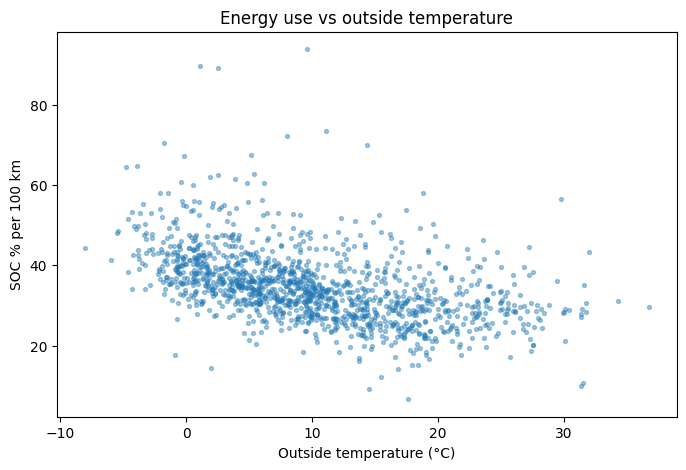

Spearman (temperature): -0.56
Spearman (mean speed): -0.04


In [15]:
plt.figure(figsize=(8, 5))
plt.scatter(energy["ambient_temp_mean"], energy["soc_per_100km"], s=8, alpha=0.4)
plt.title("Energy use vs outside temperature")
plt.xlabel("Outside temperature (°C)")
plt.ylabel("SOC % per 100 km")
plt.show()

print("Spearman (temperature):", round(spearmanr(energy["ambient_temp_mean"], energy["soc_per_100km"]).statistic, 2))
print("Spearman (mean speed):", round(spearmanr(energy["speed_mean_moving"], energy["soc_per_100km"]).statistic, 2))

Colder trips use more energy. Speed alone barely matters.

**How this informs the project:** outside temperature is the strongest single driver of energy use, so it is a feature in the rest-of-trip energy model (RQ3), a control in the regime test (H2), and the basis of H1.

## 4.2 Energy use by month and car model (RQ1, RQ4)

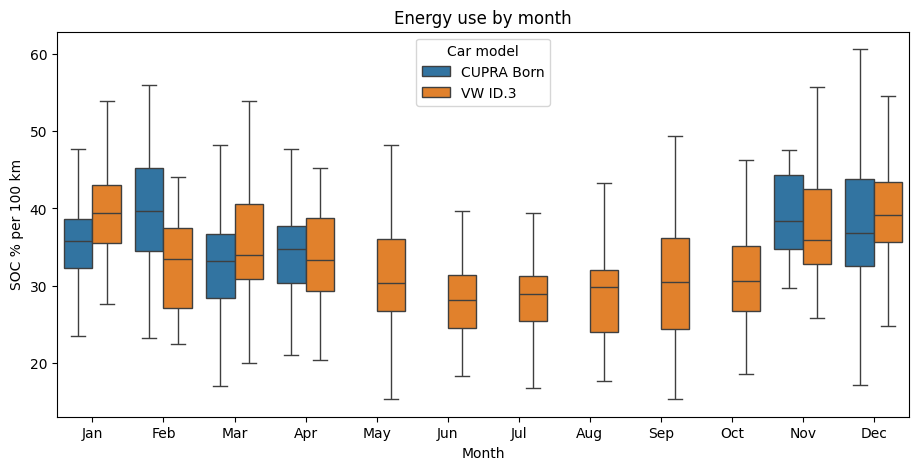

In [16]:
energy["model"] = np.where(energy["vehicle_id"].str.startswith("ID"), "VW ID.3", "CUPRA Born")

plt.figure(figsize=(11, 5))
sns.boxplot(data=energy, x="start_month", y="soc_per_100km", hue="model", showfliers=False)
plt.title("Energy use by month")
plt.xlabel("Month")
plt.ylabel("SOC % per 100 km")
plt.xticks(range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
plt.legend(title="Car model", loc="upper center")
plt.show()

Energy use is highest in winter. The CUPRAs were only logged November to May, so vehicle and season are mixed up, and our tests compare trips within the same vehicle.

**How this informs the project:** season and car model are mixed up, so the energy model gets season (month as sine/cosine) and car model as features, and every permutation test shuffles labels within a vehicle.

## 4.3 Correlation between trip features (RQ1)

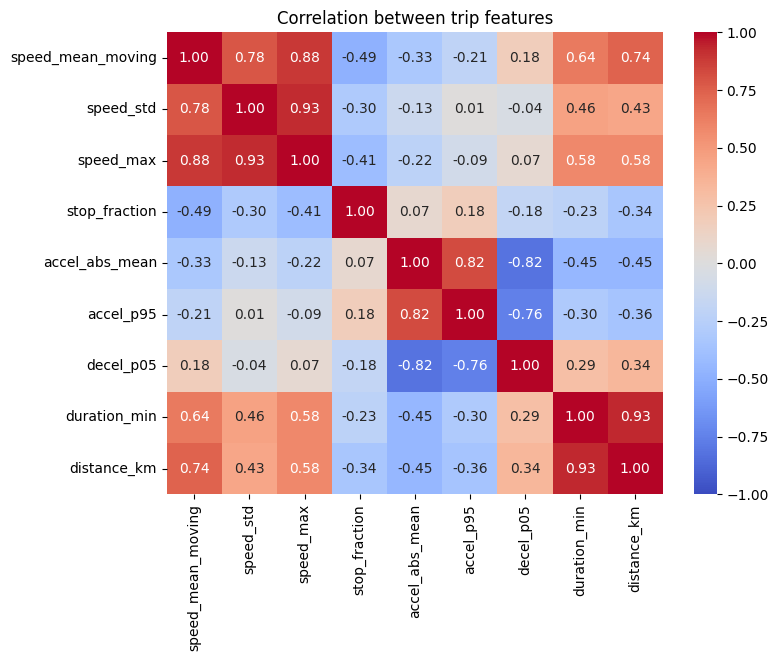

In [17]:
candidates = ["speed_mean_moving", "speed_std", "speed_max", "stop_fraction",
              "accel_abs_mean", "accel_p95", "decel_p05", "duration_min", "distance_km"]

plt.figure(figsize=(8, 6))
sns.heatmap(trips[candidates].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between trip features")
plt.show()

Distance and duration are highly correlated (0.93), as are max speed and speed SD (0.93), so we keep one of each pair (duration and speed SD) for clustering. The three acceleration features are also correlated (|r| ≈ 0.8), but they describe different parts of driving style (overall, hard acceleration, hard braking), so we keep all three.

**How this informs the project:** keeping them gives acceleration extra weight in K-Means, which is one reason we also fit a Gaussian Mixture Model with full covariance (6.1.3).

## 4.4 Battery temperature coverage and 5-minute change (RQ2)

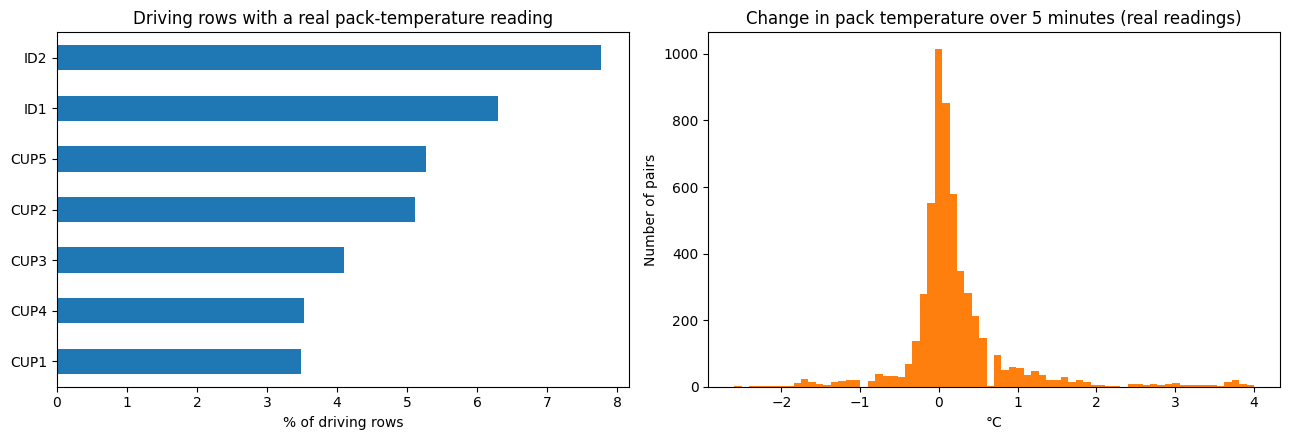

Real readings in driving rows: 6.1 %
5-minute pairs: 5401
Share of 5-minute changes within ±0.5 °C: 80.6 %
95th percentile of the 5-minute rise: 1.3 °C


In [18]:
observed_share = driving.groupby("vehicle_id")["bat_temp_observed"].mean().mul(100).sort_values()

real = tel.loc[tel["trip_id"].notna() & tel["bat_temp_observed"], ["trip_id", "ts", "bat_temp"]]
later = real.rename(columns={"ts": "ts_later", "bat_temp": "bat_temp_later"}).sort_values("ts_later")
pairs = pd.merge_asof(real.assign(ts_later=real["ts"] + pd.Timedelta(minutes=5)).sort_values("ts_later"), later,
                      on="ts_later", by="trip_id", direction="nearest", tolerance=pd.Timedelta(seconds=20))
change_5min = (pairs["bat_temp_later"] - pairs["bat_temp"]).dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
observed_share.plot.barh(ax=axes[0], color="tab:blue")
axes[0].set_title("Driving rows with a real pack-temperature reading")
axes[0].set_xlabel("% of driving rows")
axes[0].set_ylabel("")
axes[1].hist(change_5min.clip(-3, 4), bins=70, color="tab:orange")
axes[1].set_title("Change in pack temperature over 5 minutes (real readings)")
axes[1].set_xlabel("°C")
axes[1].set_ylabel("Number of pairs")
plt.tight_layout()
plt.show()

print("Real readings in driving rows:", round(driving["bat_temp_observed"].mean() * 100, 1), "%")
print("5-minute pairs:", len(change_5min))
print("Share of 5-minute changes within ±0.5 °C:", round((change_5min.abs() <= 0.5).mean() * 100, 1), "%")
print("95th percentile of the 5-minute rise:", round(change_5min.quantile(0.95), 2), "°C")

Only 6.1% of driving rows have a real pack-temperature reading (from 3.5% for CUP1 to 7.8% for ID2); the rest of the `bat_temp` column is interpolated. Most 5-minute changes are small: 81% are within ±0.5 °C, and the 95th percentile rise is 1.3 °C.

**How this informs the project:**
- The RQ2 target and the "current temperature" feature use only real readings, so interpolation cannot leak future values into the model.
- "Temperature stays the same" (persistence) is a strong baseline that the models must beat.
- The rare large rises matter most for thermal management, so we also report RMSE, which penalises large errors more.

# Part 5: Feature Engineering

## 5.1 Clustering features (RQ1)

In [19]:
cluster_features = ["speed_mean_moving", "speed_std", "stop_fraction",
                    "accel_abs_mean", "accel_p95", "decel_p05", "duration_min"]

X = trips[cluster_features].copy()
X["duration_min"] = np.log1p(X["duration_min"])
X_scaled = StandardScaler().fit_transform(X)

Duration is log-transformed because it is heavily skewed. All features are scaled because K-Means uses distances.

## 5.2 Battery temperature features (RQ2)

In [20]:
HORIZON = pd.Timedelta(minutes=5)

d = tel[tel["trip_id"].notna()].sort_values(["trip_id", "ts"]).reset_index(drop=True)
d["accel_abs"] = d["accel_ms2"].abs()
d["is_id3"] = d["vehicle_id"].str.startswith("ID").astype(int)
d["trip_elapsed_min"] = d["trip_elapsed_s"] / 60

# Current temperature = last REAL reading at or before t (no interpolation, so no future information)
d["temp_obs"] = d["bat_temp"].where(d["bat_temp_observed"])
d["obs_ts"] = d["ts"].where(d["bat_temp_observed"])
d["temp_now"] = d.groupby("trip_id")["temp_obs"].ffill()
d["temp_age_s"] = (d["ts"] - d.groupby("trip_id")["obs_ts"].ffill()).dt.total_seconds()

# Operating conditions over the past 5 minutes (rolling windows only look backwards)
past = d.set_index("ts").groupby("trip_id")
d["speed_mean_5m"] = past["speed"].rolling("300s").mean().to_numpy()
d["speed_max_5m"] = past["speed"].rolling("300s").max().to_numpy()
d["accel_abs_5m"] = past["accel_abs"].rolling("300s").mean().to_numpy()
d["aux_power_5m"] = past["hv_aux_power"].rolling("300s").mean().to_numpy()


def value_before(df, col, delta):
    """Value of `col` in the same trip `delta` earlier (within 60 s), or NaN."""
    left = df[["trip_id"]].assign(ts_past=df["ts"] - delta).reset_index().sort_values("ts_past")
    right = df[["trip_id", "ts", col]].dropna().rename(columns={"ts": "ts_past", col: "past"}).sort_values("ts_past")
    merged = pd.merge_asof(left, right, on="ts_past", by="trip_id", direction="backward", tolerance=pd.Timedelta(seconds=60))
    return merged.set_index("index")["past"].reindex(df.index)


d["temp_change_5m"] = d["temp_now"] - value_before(d, "temp_now", HORIZON)
d["outlet_change_5m"] = d["bat_outlet_temp"] - value_before(d, "bat_outlet_temp", HORIZON)

# Target: the real pack-temperature reading 5 minutes later (within ±20 s), same trip
real = d.loc[d["bat_temp_observed"], ["trip_id", "ts", "bat_temp"]]
real = real.rename(columns={"ts": "ts_future", "bat_temp": "temp_future"}).sort_values("ts_future")
left = d[["trip_id"]].assign(ts_future=d["ts"] + HORIZON).reset_index().sort_values("ts_future")
target = pd.merge_asof(left, real, on="ts_future", by="trip_id", direction="nearest", tolerance=pd.Timedelta(seconds=20))
d["temp_future"] = target.set_index("index")["temp_future"].reindex(d.index)

TEMP_FEATURES = ["temp_now", "temp_age_s", "temp_change_5m", "speed_mean_5m", "speed_max_5m", "accel_abs_5m",
                 "aux_power_5m", "ambient_temp", "bat_outlet_temp", "outlet_change_5m", "soc", "trip_elapsed_min", "is_id3"]

temp_data = d[d["temp_future"].notna() & d["temp_now"].notna() & (d["temp_age_s"] <= 600) & (d["trip_elapsed_s"] >= 300)]
temp_data = temp_data[temp_data["ts"].dt.second % 30 == 0].reset_index(drop=True)   # one row every 30 s

print("Forecasting rows:", len(temp_data), "| trips:", temp_data["trip_id"].nunique(),
      "| vehicles:", temp_data["vehicle_id"].nunique())
temp_data[TEMP_FEATURES + ["temp_future"]].describe().T.round(2)

Forecasting rows: 8484 | trips: 912 | vehicles: 7


,count,mean,std,min,25%,50%,75%,max
temp_now,8484.0,20.70,7.24,3.69,15.19,19.90,26.60,42.00
temp_age_s,8484.0,135.15,146.68,0.00,20.00,80.00,210.00,600.00
temp_change_5m,7386.0,0.16,0.82,-6.60,0.00,0.00,0.30,9.50
speed_mean_5m,8484.0,71.48,41.32,0.07,31.09,73.39,111.22,156.78
speed_max_5m,8484.0,96.35,37.18,2.11,60.47,107.78,126.90,160.23
accel_abs_5m,8484.0,0.17,0.10,0.00,0.09,0.15,0.23,0.61
aux_power_5m,8473.0,1114.84,887.46,0.30,561.74,879.76,1408.73,9377.66
ambient_temp,8332.0,11.61,7.91,-9.50,5.50,11.00,17.50,38.50
bat_outlet_temp,8149.0,16.10,7.92,0.50,10.00,15.00,22.00,37.00
outlet_change_5m,7953.0,0.00,1.50,-16.00,0.00,0.00,0.00,19.00


Each row is a moment *t* during a trip. Every feature uses only data up to *t*: the last real pack-temperature reading and its age, the temperature change over the past 5 minutes, speed, acceleration and heater/AC power over the past 5 minutes, outside and coolant temperature, SOC, time into the trip, and car model. The target is the real reading 5 minutes later. We start at 5 minutes into the trip so every row has a full 5-minute history, and keep one row every 30 seconds to limit near-duplicate rows.

## 5.3 Early-trip features (RQ3)

In [21]:
EARLY_S = 300   # the first 5 minutes of a trip

early = tel[tel["trip_id"].notna() & (tel["trip_elapsed_s"] < EARLY_S)].copy()
early["moving"] = early["speed"] > 2
g = early.groupby("trip_id")
early_features = pd.DataFrame({
    "early_speed_mean": g["speed"].mean(),
    "early_speed_std": g["speed"].std(),
    "early_speed_max": g["speed"].max(),
    "early_stop_fraction": 1 - g["moving"].mean(),
    "early_accel_abs": g["accel_ms2"].apply(lambda s: s.abs().mean()),
    "early_accel_p95": g["accel_ms2"].quantile(0.95),
    "early_dist_km": g["dist_km"].sum(),
    "early_ambient_temp": g["ambient_temp"].mean(),
    "early_aux_power": g["hv_aux_power"].mean(),
    "early_outlet_temp": g["bat_outlet_temp"].mean(),
    "soc_start": g["soc"].first(),
    "soc_at_5min": g["soc"].last(),
}).reset_index()

rest = trips[["trip_id", "vehicle_id", "start_ts", "distance_km", "duration_min", "soc_end"]].merge(early_features, on="trip_id")
rest["early_soc_used"] = rest["soc_start"] - rest["soc_at_5min"]
rest["rest_km"] = rest["distance_km"] - rest["early_dist_km"]
rest["rest_soc_per_100km"] = 100 * (rest["soc_at_5min"] - rest["soc_end"]) / rest["rest_km"]
rest["start_hour"] = rest["start_ts"].dt.hour
rest["month_sin"] = np.sin(2 * np.pi * rest["start_ts"].dt.month / 12)
rest["month_cos"] = np.cos(2 * np.pi * rest["start_ts"].dt.month / 12)
rest["is_id3"] = rest["vehicle_id"].str.startswith("ID").astype(int)

ENERGY_FEATURES = ["early_speed_mean", "early_speed_std", "early_speed_max", "early_stop_fraction", "early_accel_abs",
                   "early_accel_p95", "early_dist_km", "early_ambient_temp", "early_aux_power", "early_outlet_temp",
                   "soc_start", "early_soc_used", "start_hour", "month_sin", "month_cos", "is_id3"]

energy_data = rest[(rest["duration_min"] > 10) & (rest["rest_km"] >= 5)
                   & rest["rest_soc_per_100km"].between(5, 100)].reset_index(drop=True)
print("Trips for the rest-of-trip model:", len(energy_data), "| vehicles:", energy_data["vehicle_id"].nunique())
energy_data[ENERGY_FEATURES + ["rest_soc_per_100km"]].describe().T.round(2)

Trips for the rest-of-trip model: 1131 | vehicles: 7


,count,mean,std,min,25%,50%,75%,max
early_speed_mean,1131.0,37.72,24.49,0.72,20.06,29.65,49.73,153.28
early_speed_std,1131.0,22.48,10.29,0.09,15.30,19.12,29.08,58.32
early_speed_max,1131.0,74.79,33.71,4.00,48.56,61.36,106.00,160.13
early_stop_fraction,1131.0,0.15,0.14,0.00,0.03,0.13,0.23,0.93
early_accel_abs,1131.0,0.25,0.08,0.00,0.20,0.25,0.30,0.50
early_accel_p95,1131.0,0.62,0.20,0.00,0.49,0.62,0.75,1.34
early_dist_km,1131.0,3.03,1.99,0.03,1.61,2.41,4.07,11.57
early_ambient_temp,1087.0,9.99,8.06,-9.42,3.75,9.00,15.52,35.33
early_aux_power,1084.0,1937.17,1516.13,0.26,868.26,1519.20,2542.33,9424.33
early_outlet_temp,1043.0,13.37,7.86,0.77,7.18,11.97,18.88,36.73


One row per trip. Features describe only the first 5 minutes (speed, stops, acceleration, distance, outside temperature, heater/AC power, coolant temperature, SOC used so far) plus things known at the start (time of day, season as sine/cosine of the month, car model). The target is SOC % per 100 km for the **rest** of the trip. We keep trips longer than 10 minutes with at least 5 km left, so SOC rounding does not dominate. Whole-trip columns (including the driving regime, which is clustered on the full trip) are not used, because they would leak the future.

# Part 6: Modeling

## 6.1 Driving regimes (RQ1)

### 6.1.1 Baseline: speed bins

In [22]:
def cluster_scores(labels):
    return {
        "silhouette": silhouette_score(X_scaled, labels),
        "davies_bouldin": davies_bouldin_score(X_scaled, labels),
        "calinski_harabasz": calinski_harabasz_score(X_scaled, labels),
    }


baseline_labels = pd.cut(trips["speed_mean_moving"], bins=[0, 30, 60, np.inf], labels=False)
cluster_scores(baseline_labels)

{'silhouette': 0.13420665668664328,
 'davies_bouldin': 1.9450173772941663,
 'calinski_harabasz': 591.5508545457469}

### 6.1.2 K-Means

In [23]:
k_results = []
for k in range(2, 9):
    labels = KMeans(n_clusters=k, n_init=20, random_state=0).fit_predict(X_scaled)
    k_results.append({"k": k, **cluster_scores(labels)})

pd.DataFrame(k_results).set_index("k").round(3)

,silhouette,davies_bouldin,calinski_harabasz
k,,,
2,0.313,1.282,1058.783
3,0.265,1.273,1026.861
4,0.274,1.182,966.579
5,0.258,1.215,916.088
6,0.236,1.292,838.026
7,0.229,1.253,782.033
8,0.213,1.307,748.643


We use k = 4. It has the lowest Davies-Bouldin score, and k = 2 only separates short and long trips.

In [24]:
kmeans = KMeans(n_clusters=4, n_init=50, random_state=0).fit(X_scaled)

regime_names = ["Short urban", "Dynamic urban", "Mixed suburban", "Highway"]
cluster_speed = trips.groupby(kmeans.labels_)["speed_mean_moving"].median().sort_values()
trips["regime"] = pd.Categorical(pd.Series(kmeans.labels_).map(dict(zip(cluster_speed.index, regime_names))),
                                 categories=regime_names)

pd.DataFrame({"Baseline": cluster_scores(baseline_labels), "K-Means": cluster_scores(kmeans.labels_)}).T.round(3)

,silhouette,davies_bouldin,calinski_harabasz
Baseline,0.134,1.945,591.551
K-Means,0.274,1.182,966.579


In [25]:
trips.groupby("regime", observed=True)[cluster_features].median().round(2)

,speed_mean_moving,speed_std,stop_fraction,accel_abs_mean,accel_p95,decel_p05,duration_min
regime,,,,,,,
Short urban,24.22,15.20,0.16,0.21,0.49,-0.48,8.00
Dynamic urban,32.00,19.80,0.17,0.29,0.71,-0.69,12.33
Mixed suburban,56.51,36.23,0.09,0.22,0.56,-0.56,23.08
Highway,95.41,35.13,0.02,0.13,0.31,-0.33,70.50


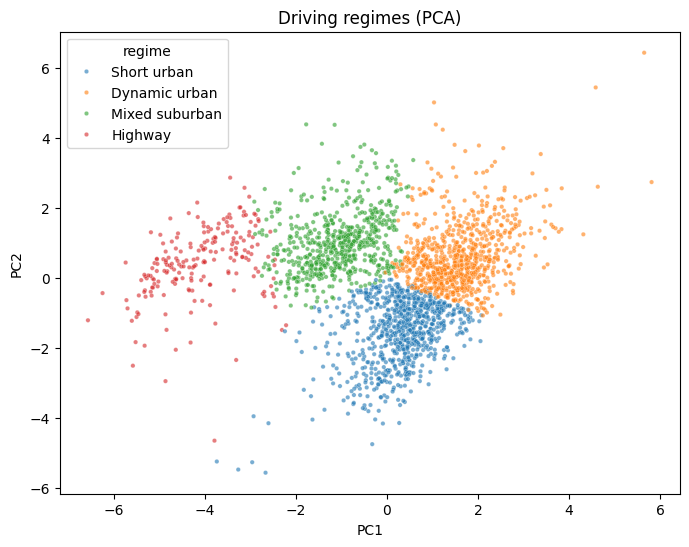

In [26]:
pcs = PCA(n_components=2).fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=trips["regime"], s=10, alpha=0.6)
plt.title("Driving regimes (PCA)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

K-Means scores better than the speed-bin baseline on all three metrics. The regimes overlap a bit, so driving style is more of a spectrum.

### 6.1.3 Gaussian Mixture Model

Model 2 for RQ1. A Gaussian Mixture Model gives soft (probabilistic) assignments and, with full covariance, allows elongated clusters and correlated features, which fits the overlap seen in the PCA plot. We choose k with BIC and compare it with K-Means at k = 4.

In [27]:
gmm_results = []
for k in range(2, 9):
    gmm = GaussianMixture(n_components=k, covariance_type="full", n_init=5, random_state=0).fit(X_scaled)
    gmm_results.append({"k": k, "BIC": gmm.bic(X_scaled), **cluster_scores(gmm.predict(X_scaled))})

pd.DataFrame(gmm_results).set_index("k").round(3)

,BIC,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,31016.027,0.291,1.383,968.147
3,29737.036,0.173,1.924,615.304
4,28969.629,0.180,2.265,531.534
5,28622.057,0.145,2.385,455.526
6,28679.661,0.119,2.359,432.161
7,28361.061,0.131,2.185,431.687
8,28418.104,0.087,2.489,346.738


In [28]:
gmm4 = GaussianMixture(n_components=4, covariance_type="full", n_init=10, random_state=0).fit(X_scaled)
gmm_labels = gmm4.predict(X_scaled)
gmm_confidence = gmm4.predict_proba(X_scaled).max(axis=1)

kmeans_stability = [adjusted_rand_score(kmeans.labels_, KMeans(n_clusters=4, n_init=10, random_state=s).fit_predict(X_scaled))
                    for s in range(1, 11)]

print("K-Means stability across 10 random seeds (mean ARI):", round(np.mean(kmeans_stability), 3))
print("Agreement between K-Means and GMM (ARI):", round(adjusted_rand_score(kmeans.labels_, gmm_labels), 3))
print("GMM trips assigned with > 90% probability:", round((gmm_confidence > 0.9).mean() * 100, 1), "%")

cluster_comparison = pd.DataFrame({
    "Baseline: speed bins": cluster_scores(baseline_labels),
    "K-Means (k=4)": cluster_scores(kmeans.labels_),
    "GMM (k=4)": cluster_scores(gmm_labels),
}).T.round(3)
cluster_comparison

K-Means stability across 10 random seeds (mean ARI): 0.998
Agreement between K-Means and GMM (ARI): 0.389
GMM trips assigned with > 90% probability: 76.9 %


,silhouette,davies_bouldin,calinski_harabasz
Baseline: speed bins,0.134,1.945,591.551
K-Means (k=4),0.274,1.182,966.579
GMM (k=4),0.179,2.319,519.211


In [29]:
pd.crosstab(trips["regime"], pd.Series(gmm_labels, name="GMM cluster", index=trips.index))

GMM cluster,0,1,2,3
regime,,,,
Short urban,625,125,2,40
Dynamic urban,598,146,0,38
Mixed suburban,4,33,93,482
Highway,0,1,194,8


BIC is lowest at k = 7, so on likelihood alone the GMM would use more clusters, but those clusters are poorly separated (silhouette 0.13). At k = 4 the GMM scores worse than K-Means on all three metrics (silhouette 0.18 vs 0.27, Davies-Bouldin 2.32 vs 1.18). These metrics favour round clusters, so they lean towards K-Means; the crosstab is more telling. The GMM merges *Short urban* and *Dynamic urban* into one cluster and keeps *Mixed suburban* and *Highway* mostly separate (agreement ARI = 0.39). It assigns 77% of trips with more than 90% probability. K-Means is very stable (ARI = 0.998 across 10 random seeds).

**Decision:** we keep the K-Means regimes for the hypothesis tests because they are stable and easy to interpret, and report the GMM as a check: the urban vs suburban vs highway split is robust, while the line between the two urban regimes is soft.

## 6.2 Battery temperature forecasting (RQ2)

**Approach.** The models predict the *change* in temperature over the next 5 minutes; the forecast is current temperature + predicted change.

| | Model | Why |
| --- | --- | --- |
| Baseline | Persistence: temperature in 5 min = current temperature | The standard forecasting baseline; hard to beat because temperature changes slowly |
| Reference | Linear regression (Ridge) | Interpretable; shows how much a linear effect of the features explains |
| Model 1 | Random Forest | Captures non-linear effects and interactions (e.g. speed × outside temperature); robust with little tuning |
| Model 2 | XGBoost | Usually the most accurate on tabular data; handles missing values natively |

**Validation:** 5-fold GroupKFold by trip, so rows from the same trip are never in both training and test data (neighbouring rows are almost identical). **Metrics:** MAE and RMSE in °C, R² of the temperature, and R² of the 5-minute change (the harder number, since predicting temperature ≈ current temperature already gives a high R²). Every model is scored on the same folds as the baseline.

In [30]:
def regression_scores(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
            "R2": r2_score(y_true, y_pred)}


def cross_validate(models, X, y, groups, splitter):
    """Out-of-fold predictions for every model, using the same folds for all of them."""
    predictions = {name: np.zeros(len(y)) for name in models}
    for train, test in splitter.split(X, y, groups):
        for name, make_model in models.items():
            model = make_model().fit(X.iloc[train], y.iloc[train])
            predictions[name][test] = model.predict(X.iloc[test])
    return predictions

In [31]:
X_temp = temp_data[TEMP_FEATURES]
y_change = temp_data["temp_future"] - temp_data["temp_now"]

temp_models = {
    "Baseline: persistence": lambda: DummyRegressor(strategy="constant", constant=0.0),
    "Linear regression (Ridge)": lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest": lambda: make_pipeline(SimpleImputer(strategy="median"),
                                           RandomForestRegressor(n_estimators=200, min_samples_leaf=20, n_jobs=-1, random_state=0)),
    "XGBoost": lambda: XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.8,
                                    colsample_bytree=0.8, n_jobs=-1, random_state=0),
}

temp_pred = cross_validate(temp_models, X_temp, y_change, temp_data["trip_id"], GroupKFold(n_splits=5))

temp_results = pd.DataFrame({name: regression_scores(temp_data["temp_future"], temp_data["temp_now"] + p)
                             for name, p in temp_pred.items()}).T
temp_results["R2 of 5-min change"] = [r2_score(y_change, p) for p in temp_pred.values()]
temp_results["MAE vs baseline"] = temp_results["MAE"] / temp_results.loc["Baseline: persistence", "MAE"] - 1
temp_results.round(3)

,MAE,RMSE,R2,R2 of 5-min change,MAE vs baseline
Baseline: persistence,0.546,0.959,0.981,-0.063,0.000
Linear regression (Ridge),0.448,0.693,0.990,0.445,-0.179
Random Forest,0.350,0.596,0.993,0.590,-0.359
XGBoost,0.314,0.519,0.994,0.689,-0.426


Both models beat persistence on the same folds. XGBoost has the lowest error: **MAE 0.31 °C vs 0.55 °C for persistence (43% lower)** and RMSE 0.52 vs 0.96 °C. It explains 69% of the variance in the 5-minute change, while persistence explains none. Random Forest is close (MAE 0.35 °C). The linear model improves by only 18%, so the effects are non-linear. R² of the temperature itself is above 0.98 for every model, including persistence, which is why we judge models on MAE/RMSE and on R² of the change.

In [32]:
# Harder check: train on 6 cars, test on the 7th (leave one vehicle out)
lovo_temp = cross_validate({k: temp_models[k] for k in ["Baseline: persistence", "XGBoost"]},
                           X_temp, y_change, temp_data["vehicle_id"], LeaveOneGroupOut())
pd.DataFrame({name: regression_scores(temp_data["temp_future"], temp_data["temp_now"] + p)
              for name, p in lovo_temp.items()}).T.round(3)

,MAE,RMSE,R2
Baseline: persistence,0.546,0.959,0.981
XGBoost,0.348,0.558,0.994


On a car that was not in the training data, XGBoost still reaches MAE 0.35 °C vs 0.55 °C for persistence, so the model generalises across vehicles rather than learning one car's behaviour.

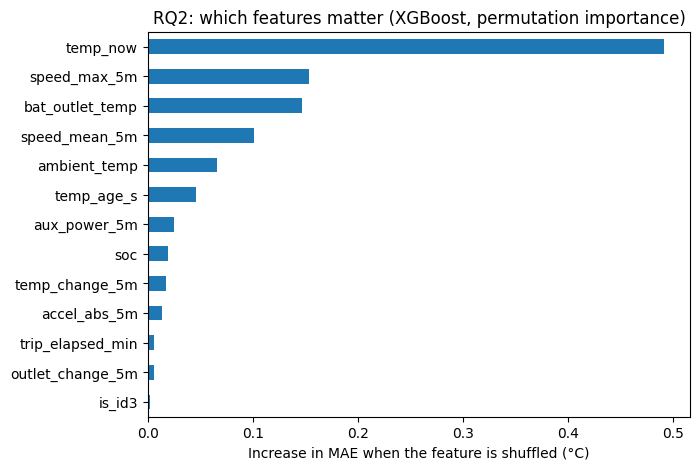

In [33]:
train, test = next(GroupKFold(n_splits=5).split(X_temp, y_change, temp_data["trip_id"]))
xgb_temp = temp_models["XGBoost"]().fit(X_temp.iloc[train], y_change.iloc[train])
importance = permutation_importance(xgb_temp, X_temp.iloc[test], y_change.iloc[test], n_repeats=5,
                                    scoring="neg_mean_absolute_error", random_state=0)
temp_importance = pd.Series(importance.importances_mean, index=TEMP_FEATURES).sort_values()

temp_importance.plot.barh(figsize=(7, 5), color="tab:blue")
plt.title("RQ2: which features matter (XGBoost, permutation importance)")
plt.xlabel("Increase in MAE when the feature is shuffled (°C)")
plt.show()

The current temperature matters most, as expected. Next come recent maximum and mean speed, coolant outlet temperature and outside temperature: higher speeds heat the pack, while the coolant and outside air set how fast it cools.

**Trade-offs:** XGBoost is the most accurate but the least transparent; permutation importance and the Ridge model give the interpretable view. With 8,484 rows from 912 trips, tree models are a good fit; an LSTM would need more data and stays a stretch goal.

## 6.3 Rest-of-trip energy (RQ3)

**Approach.**

| | Model | Why |
| --- | --- | --- |
| Baseline | Training-set mean | What we would predict knowing nothing about the trip |
| Baseline from the proposal | Lasso (L1-regularised linear regression, alpha chosen by inner 5-fold CV) | Interpretable; shows which early-trip signals matter linearly and drops weak ones |
| Model 1 | Random Forest | Non-linear effects, e.g. heating only matters below about 10 °C |
| Model 2 | XGBoost | Strong on small tabular data with regularisation |

**Validation:** 5-fold cross-validation with shuffling (each trip is one row, so trips never overlap between folds), plus a leave-one-vehicle-out check. **Metrics:** MAE and RMSE in SOC %/100 km, and R². All models use the same folds.

In [34]:
X_energy = energy_data[ENERGY_FEATURES]
y_energy = energy_data["rest_soc_per_100km"]

energy_models = {
    "Baseline: training mean": lambda: DummyRegressor(strategy="mean"),
    "Lasso (proposal baseline)": lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                                       LassoCV(cv=5, random_state=0)),
    "Random Forest": lambda: make_pipeline(SimpleImputer(strategy="median"),
                                           RandomForestRegressor(n_estimators=500, min_samples_leaf=5, n_jobs=-1, random_state=0)),
    "XGBoost": lambda: XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8,
                                    colsample_bytree=0.8, min_child_weight=5, n_jobs=-1, random_state=0),
}

energy_pred = cross_validate(energy_models, X_energy, y_energy, None,   # one row per trip, so plain shuffled K-fold
                             KFold(n_splits=5, shuffle=True, random_state=0))

energy_results = pd.DataFrame({name: regression_scores(y_energy, p) for name, p in energy_pred.items()}).T
energy_results["MAE vs baseline"] = energy_results["MAE"] / energy_results.loc["Baseline: training mean", "MAE"] - 1
energy_results.round(3)

,MAE,RMSE,R2,MAE vs baseline
Baseline: training mean,5.968,7.691,-0.002,0.000
Lasso (proposal baseline),5.024,6.654,0.250,-0.158
Random Forest,4.792,6.469,0.291,-0.197
XGBoost,4.754,6.362,0.315,-0.203


Predicting the rest of a trip from its first 5 minutes is harder. XGBoost has the lowest error: **MAE 4.75 vs 5.97 SOC %/100 km for the mean baseline (20% lower)**, R² = 0.32. Random Forest (4.79) and Lasso (5.02) are close, so a simple linear model already captures most of the gain. Part of the remaining error is noise in the target: SOC is logged in 0.4% steps, so a 10 km remainder carries up to ±4 SOC %/100 km of rounding alone.

In [35]:
lovo_energy = cross_validate({k: energy_models[k] for k in ["Baseline: training mean", "Lasso (proposal baseline)", "XGBoost"]},
                             X_energy, y_energy, energy_data["vehicle_id"], LeaveOneGroupOut())
pd.DataFrame({name: regression_scores(y_energy, p) for name, p in lovo_energy.items()}).T.round(3)

,MAE,RMSE,R2
Baseline: training mean,6.062,7.788,-0.027
Lasso (proposal baseline),5.346,7.049,0.158
XGBoost,5.253,7.017,0.166


On an unseen car every model loses accuracy (XGBoost MAE 5.25, R² = 0.17), but still beats the baseline (6.06). The cars differ (two models, different seasons logged), so we report both validation schemes.

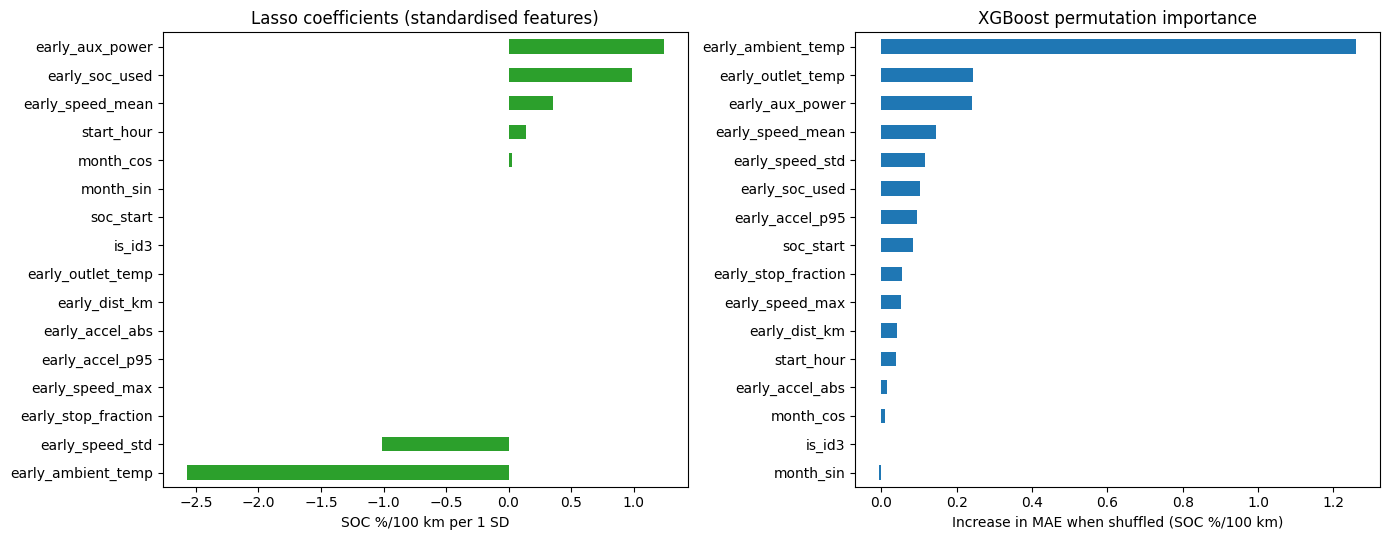

Features dropped by Lasso: ['early_speed_max', 'early_stop_fraction', 'early_accel_abs', 'early_accel_p95', 'early_dist_km', 'early_outlet_temp', 'soc_start', 'month_sin', 'is_id3']


In [36]:
lasso = energy_models["Lasso (proposal baseline)"]().fit(X_energy, y_energy)
lasso_coef = pd.Series(lasso[-1].coef_, index=ENERGY_FEATURES)

train, test = next(KFold(n_splits=5, shuffle=True, random_state=0).split(X_energy))
xgb_energy = energy_models["XGBoost"]().fit(X_energy.iloc[train], y_energy.iloc[train])
importance = permutation_importance(xgb_energy, X_energy.iloc[test], y_energy.iloc[test], n_repeats=20,
                                    scoring="neg_mean_absolute_error", random_state=0)
energy_importance = pd.Series(importance.importances_mean, index=ENERGY_FEATURES)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
lasso_coef.sort_values().plot.barh(ax=axes[0], color="tab:green")
axes[0].set_title("Lasso coefficients (standardised features)")
axes[0].set_xlabel("SOC %/100 km per 1 SD")
energy_importance.sort_values().plot.barh(ax=axes[1], color="tab:blue")
axes[1].set_title("XGBoost permutation importance")
axes[1].set_xlabel("Increase in MAE when shuffled (SOC %/100 km)")
plt.tight_layout()
plt.show()
print("Features dropped by Lasso:", list(lasso_coef[lasso_coef == 0].index))

Both views agree that outside temperature is the main driver, with heater/AC power next. XGBoost also uses coolant temperature, and Lasso also uses early speed and the SOC already used. Lasso keeps 7 of the 16 features. Its error is only about 6% higher than XGBoost's.

**Trade-off:** we use Lasso to explain the effects and XGBoost for the best accuracy.

## 6.4 Model comparison

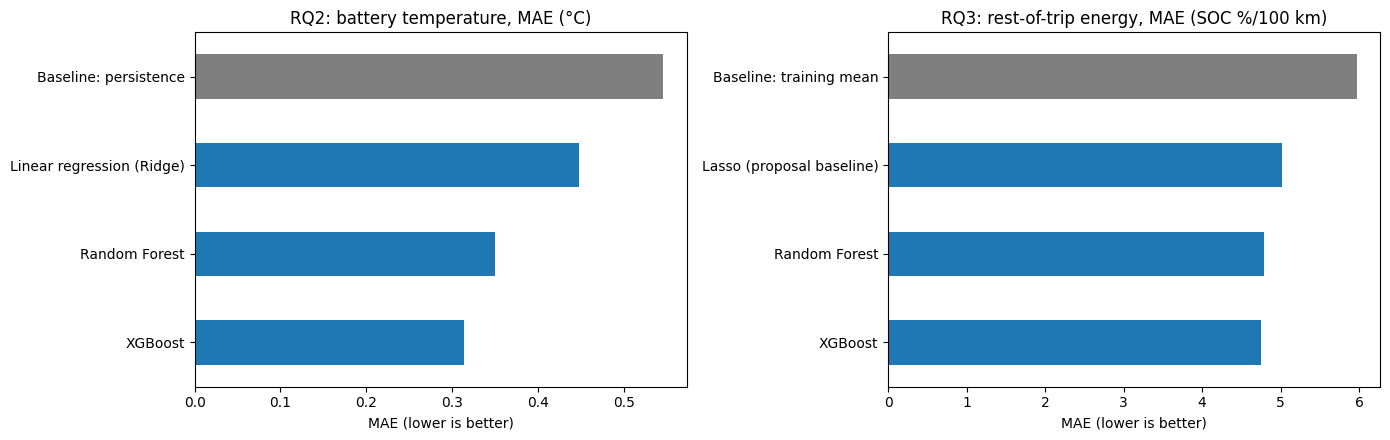

MAE  \
RQ2: battery temperature in 5 min (°C)  Baseline: persistence      0.546   
                                        Linear regression (Ridge)  0.448   
                                        Random Forest              0.350   
                                        XGBoost                    0.314   
RQ3: rest-of-trip energy (SOC %/100 km) Baseline: training mean    5.968   
                                        Lasso (proposal baseline)  5.024   
                                        Random Forest              4.792   
                                        XGBoost                    4.754   

                                                                    RMSE  \
RQ2: battery temperature in 5 min (°C)  Baseline: persistence      0.959   
                                        Linear regression (Ridge)  0.693   
                                        Random Forest              0.596   
                                        XGBoost                    0.519   
RQ3: rest-of-trip energy (SOC %/100 km) Baseline: training mean    7.691   
                                        Lasso (proposal baseline)  6.654   
                                        Random Forest              6.469   
                                        XGBoost                    6.362   

                                                                      R2  \
RQ2: battery temperature in 5 min (°C)  Baseline: persistence      0.981   
                                        Linear regression (Ridge)  0.990   
                                        Random Forest              0.993   
                                        XGBoost                    0.994   
RQ3: rest-of-trip energy (SOC %/100 km) Baseline: training mean   -0.002   
                                        Lasso (proposal baseline)  0.250   
                                        Random Forest              0.291   
                                        XGBoost                    0.315   

                                                                   MAE vs baseline  
RQ2: battery temperature in 5 min (°C)  Baseline: persistence                0.000  
                                        Linear regression (Ridge)           -0.179  
                                        Random Forest                       -0.359  
                                        XGBoost                             -0.426  
RQ3: rest-of-trip energy (SOC %/100 km) Baseline: training mean              0.000  
                                        Lasso (proposal baseline)           -0.158  
                                        Random Forest                       -0.197  
                                        XGBoost                             -0.203

In [37]:
comparison = pd.concat({
    "RQ2: battery temperature in 5 min (°C)": temp_results[["MAE", "RMSE", "R2", "MAE vs baseline"]],
    "RQ3: rest-of-trip energy (SOC %/100 km)": energy_results[["MAE", "RMSE", "R2", "MAE vs baseline"]],
}).round(3)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (title, table) in zip(axes, [("RQ2: battery temperature, MAE (°C)", temp_results),
                                     ("RQ3: rest-of-trip energy, MAE (SOC %/100 km)", energy_results)]):
    colors = ["tab:gray" if name.startswith("Baseline") else "tab:blue" for name in table.index]
    table["MAE"].plot.barh(ax=ax, color=colors)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("MAE (lower is better)")
plt.tight_layout()
plt.show()
comparison

| Task | Baseline | Best model | MAE reduction |
| --- | --- | --- | --- |
| RQ2: battery temperature in 5 min | Persistence, MAE 0.55 °C | XGBoost, MAE 0.31 °C | 43% |
| RQ3: rest-of-trip energy | Training mean, MAE 5.97 SOC %/100 km | XGBoost, MAE 4.75 SOC %/100 km | 20% |

**How we compare models:** the same rows and folds for every model; MAE as the main metric (in the target's units and robust to outliers), RMSE to check large errors, and R² for explained variance. Whether the improvement over the baseline is real is tested in 7.4 and 7.5. Hyperparameters are fixed, reasonable settings for now; tuning with nested cross-validation is the next step.

# Part 7: Hypothesis Testing

Permutation tests with 10,000 shuffles. Each trip is one data point, and labels are shuffled within each vehicle.

In [38]:
rng = np.random.default_rng(0)


def permutation_test(df, label_col, value_col, statistic, n_perm=10_000):
    labels = df[label_col].to_numpy()
    values = df[value_col].to_numpy()
    vehicles = df["vehicle_id"].to_numpy()
    observed = statistic(labels, values)

    null_stats = []
    for _ in range(n_perm):
        shuffled = labels.copy()
        for v in np.unique(vehicles):
            idx = np.where(vehicles == v)[0]
            shuffled[idx] = rng.permutation(labels[idx])
        null_stats.append(statistic(shuffled, values))

    p_value = (np.sum(np.array(null_stats) >= observed) + 1) / (n_perm + 1)
    return observed, p_value


def diff_in_means(labels, values):
    return values[labels == 1].mean() - values[labels == 0].mean()


def sd_of_group_means(labels, values):
    return np.std([values[labels == g].mean() for g in np.unique(labels)])

## 7.1 H1: Cold trips use more energy (RQ4)
H0: cold (< 10 °C) and warm trips use the same energy.

In [39]:
energy["cold"] = (energy["ambient_temp_mean"] < 10).astype(int)
diff, p_value = permutation_test(energy, "cold", "soc_per_100km", diff_in_means)

print("Cold - warm:", round(diff, 2), "SOC % per 100 km")
print("p-value:", round(p_value, 4))

Cold - warm: 7.75 SOC % per 100 km
p-value: 0.0001


## 7.2 H2: Energy use differs by driving regime (RQ1)
H0: energy use does not depend on regime. We also test energy adjusted for temperature.

In [40]:
energy = energy.drop(columns=["regime"], errors="ignore").merge(trips[["trip_id", "regime"]], on="trip_id")
energy["regime_code"] = energy["regime"].cat.codes

slope, intercept = np.polyfit(energy["ambient_temp_mean"], energy["soc_per_100km"], 1)
energy["soc_adjusted"] = energy["soc_per_100km"] - (intercept + slope * energy["ambient_temp_mean"])

_, p_raw = permutation_test(energy, "regime_code", "soc_per_100km", sd_of_group_means)
_, p_adjusted = permutation_test(energy, "regime_code", "soc_adjusted", sd_of_group_means)

print("p-value (raw):", round(p_raw, 4))
print("p-value (temperature-adjusted):", round(p_adjusted, 4))
energy.groupby("regime", observed=True)[["soc_per_100km", "soc_adjusted", "ambient_temp_mean"]].mean().round(2)

p-value (raw): 0.201
p-value (temperature-adjusted): 0.0002


,soc_per_100km,soc_adjusted,ambient_temp_mean
regime,,,
Short urban,35.89,0.31,8.32
Dynamic urban,35.67,0.10,8.32
Mixed suburban,33.46,-0.94,10.54
Highway,35.37,2.34,13.12


Cold trips use clearly more energy. Regime only matters once temperature is accounted for, because highway trips happen in warmer weather.

**Reading H2 carefully:** the statistic (spread of the regime means) says that at least one regime differs, not which one. After adjusting for temperature, highway trips use about 2.3 SOC %/100 km more than expected and mixed suburban trips the least, which fits air drag at high speed. The temperature adjustment is linear, which is a simplification, since heating mostly matters in the cold.

## 7.3 Robustness of H1
The 10 °C cut-off is a choice, so we repeat H1 at 5 °C and 15 °C, and also test the continuous relationship (Spearman correlation between outside temperature and energy, with temperatures shuffled within each vehicle).

In [41]:
robustness = []
for cutoff in [5, 10, 15]:
    labels = energy.assign(cold=(energy["ambient_temp_mean"] < cutoff).astype(int))
    diff, p = permutation_test(labels, "cold", "soc_per_100km", diff_in_means)
    robustness.append({"test": f"cold < {cutoff} °C vs warm", "statistic": round(diff, 2), "p-value": p})

negative_spearman = lambda temps, values: -spearmanr(temps, values).statistic
rho, p = permutation_test(energy, "ambient_temp_mean", "soc_per_100km", negative_spearman)
robustness.append({"test": "Spearman correlation (temperature vs energy)", "statistic": round(-rho, 3), "p-value": p})
pd.DataFrame(robustness)

,test,statistic,p-value
0,cold < 5 °C vs warm,8.32,0.0001
1,cold < 10 °C vs warm,7.75,0.0001
2,cold < 15 °C vs warm,6.96,0.0001
3,Spearman correlation (temperature vs energy),-0.56,0.0001


The result does not depend on the 10 °C cut-off: the cold–warm gap is 8.3, 7.8 and 7.0 SOC %/100 km at 5, 10 and 15 °C, and the Spearman correlation is −0.56. Every p-value is 0.0001, the smallest possible with 10,000 shuffles.

## 7.4 H3: Recent operating conditions improve the 5-minute temperature forecast (RQ2)
H0: the best model is no more accurate than persistence (which uses only the current temperature). We compare the absolute errors of the two on the same out-of-fold rows, average the difference per trip, and run a sign-flip permutation test over trips (10,000 random sign flips). Trips, not rows, are the unit, because rows within a trip are not independent.

In [42]:
def paired_permutation_test(errors_baseline, errors_model, groups, n_perm=10_000):
    """One-sided test that the model has a lower absolute error than the baseline.
    Errors are averaged per group (trip), then the sign of each group's difference is flipped at random."""
    diff = pd.Series(np.abs(errors_baseline) - np.abs(errors_model)).groupby(np.asarray(groups)).mean().to_numpy()
    observed = diff.mean()
    null = (rng.choice([-1, 1], size=(n_perm, len(diff))) * diff).mean(axis=1)
    return observed, (np.sum(null >= observed) + 1) / (n_perm + 1)


best_temp_model = temp_results.drop(index="Baseline: persistence")["MAE"].idxmin()
gain, p_h3 = paired_permutation_test(y_change - temp_pred["Baseline: persistence"],
                                     y_change - temp_pred[best_temp_model], temp_data["trip_id"])
print("Best model:", best_temp_model)
print("Mean MAE reduction per trip:", round(gain, 3), "°C")
print("p-value:", round(p_h3, 4))

Best model: XGBoost
Mean MAE reduction per trip: 0.223 °C
p-value: 0.0001


XGBoost lowers the absolute error by 0.22 °C per trip on average, p = 0.0001, so we reject H0: recent driving conditions add information beyond the current temperature.

## 7.5 H4: Early-trip behaviour predicts rest-of-trip energy (RQ3)
H0: the best model is no more accurate than predicting the training mean. Same sign-flip test, with each trip as one unit.

In [43]:
best_energy_model = energy_results.drop(index="Baseline: training mean")["MAE"].idxmin()
gain, p_h4 = paired_permutation_test(y_energy - energy_pred["Baseline: training mean"],
                                     y_energy - energy_pred[best_energy_model], energy_data["trip_id"])
print("Best model:", best_energy_model)
print("Mean MAE reduction per trip:", round(gain, 2), "SOC %/100 km")
print("p-value:", round(p_h4, 4))

Best model: XGBoost
Mean MAE reduction per trip: 1.21 SOC %/100 km
p-value: 0.0001


XGBoost lowers the absolute error by 1.21 SOC %/100 km per trip on average, p = 0.0001, so we reject H0: the first 5 minutes carry real information about the rest of the trip, although most of the variance (R² = 0.32) is still unexplained.

## 7.6 Summary of tests
We run four main tests (H1–H4), so we use a Bonferroni-corrected significance level of 0.05 / 4 = 0.0125.

In [44]:
pd.DataFrame([
    {"hypothesis": "H1: cold trips (< 10 °C) use more energy", "p-value": p_value},
    {"hypothesis": "H2: energy differs by regime (temperature-adjusted)", "p-value": p_adjusted},
    {"hypothesis": "H3: recent conditions improve the 5-min temperature forecast", "p-value": p_h3},
    {"hypothesis": "H4: early-trip behaviour predicts rest-of-trip energy", "p-value": p_h4},
]).assign(**{"significant at 0.0125": lambda t: t["p-value"] < 0.0125}).round(4)

,hypothesis,p-value,significant at 0.0125
0,H1: cold trips (< 10 °C) use more energy,0.0001,True
1,H2: energy differs by regime (temperature-adju...,0.0002,True
2,H3: recent conditions improve the 5-min temper...,0.0001,True
3,H4: early-trip behaviour predicts rest-of-trip...,0.0001,True


# Part 8: Conclusion

Results at the intermediate check-in:

| RQ | Result |
| --- | --- |
| RQ1: driving regimes | 4 stable regimes (silhouette 0.27 vs 0.13 for the speed-bin baseline). Energy differs by regime only after adjusting for temperature (H2, p = 0.0002). |
| RQ2: battery temperature in 5 min | XGBoost MAE 0.31 °C, 43% better than persistence, and 0.35 °C on unseen cars (H3, p = 0.0001). |
| RQ3: rest-of-trip energy | From the first 5 minutes, XGBoost is 20% better than the mean (MAE 4.75 SOC %/100 km, R² = 0.32; H4, p = 0.0001). |
| RQ4: cold weather | Cold trips (< 10 °C) use 7.8 SOC %/100 km more, robust to the cut-off (H1, p = 0.0001). |

All four tests stay significant after the Bonferroni correction.

# Part 9: Challenges & Next Steps

**Challenges**
- Sparse battery temperature: only about 6% of driving rows have a real pack-temperature reading, which limits RQ2 to 8,484 forecast rows. We use only real readings, to avoid leakage from interpolation.
- No battery current, motor RPM or odometer: energy is SOC % per 100 km (0.4% steps, so short trips are noisy), and distance comes from speed.
- Uneven data: 46 to 836 trips per car, and the CUPRAs were only logged in winter and spring, so car and season are mixed up. We shuffle within vehicle and also validate on unseen cars.

**Next steps**
- Tune hyperparameters with nested cross-validation.
- RQ2: try an LSTM on the 5-minute history if time allows, and compare pack max temperature with coolant outlet temperature as the target.
- RQ3: compare early windows of 3, 5 and 10 minutes.
- RQ1: decide whether to keep 4 regimes or merge the two urban ones (GMM result).
- RQ5 (optional): decide whether to include the battery-health dataset.

| Task | Owner | Due | Status |
| --- | --- | --- | --- |
| GMM and comparison (RQ1) | Aditya B., Aditya M. | Nov 23 | First version done (6.1.3); interpretation to finalise |
| Battery temperature models (RQ2) | Dee, Hari | Nov 26 | Baseline, Random Forest and XGBoost done; tuning and LSTM next |
| Trip energy models (RQ3) | Aditya M., Sumit | Nov 26 | Baseline, Lasso, Random Forest and XGBoost done; tuning and window length next |
| Robustness checks for tests | Hari, Aditya B. | Nov 28 | H1 robustness done (7.3); non-linear temperature adjustment for H2 next |
| Final notebook | Sumit, Aditya B. | Dec 3 | In progress |
| Slides and video | All | Dec 6 | Not started |